# Solving Inverse Problem using weighted Connectome Spectrum Electromagnetic Tomography (wCSET)

wCSET solves the following optimization problem: 
$$\hat {\mathbf s}^* = \text{argmin}_{\mathbf{s}} \lVert \mathbf{LU}\hat{\mathbf s}-\mathbf{y} \rVert_2^2 + \lambda \lVert \mathbf D\hat{\mathbf s}\rVert_2^2$$
$$ \mathbf s^* = \mathbf U \hat{\mathbf s}$$

where
- $\mathbf{s}^* \in \mathbb{R}^n$ are the reconstructed dipole strengths
- $\hat{\mathbf{s}}^* \in \mathbb{R}^n$ is the reconstructed connectome spectrum.
- $\mathbf{y} \in \mathbb{R}^m$ are the EEG measurements.
- $\mathbf L \in \mathbb{R}^{m\times n}$ is the lead field matrix.
- $\mathbf U \in \mathbb{R}^{n \times n}$ is the inverse graph Fourier transform
- $\lambda \in \mathbb{R}$ is the regularizer parameter.
- $\mathbf D \in \mathbb{R}^{n\times n}$ is a diagonal matrix weighting the harmonics.

The particularity of wCSET is that it weights the harmonic according to the gap frequencies. The idea comes from the fact that most reconstructions (CSET and sLORETA) rebuild the low frequency harmonics (integrative) and very high frequency harmonics (segregative) but not as much the center harmonics (degenerative). These frequencies are each defined by there gap frequency (low gap for degenerative and high gap for integrative/segregative). So the plan here is to enforce this imbalance to see how it affects the source reconstruction.

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- Configuration file (`config`)
- `subjects`: list of subjects to process
- `samples`: list of samples to process


🎚️ **<font color=pink>Parameters</font>**
- Regularizer parameter (`lam`)
- Depth Weighting scale (`dw`)
- Window size (`win_size`): time window around EEG peak in [s]

## ♾️ Loop

# Step Wise Run

Run the code step by step for a single subject.

## 📦 Imports

In [1]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

import pyxu.abc as pxa
import pyxu.operator as pxo
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## 🧠 Data

In [4]:
# configuration
sub    = "vepcon_sub-10"
config = mm.io.read_config("../configurations/simf.yml")
sample = "sample1"

# data
data = mm.io.read_dataset(sub, "fwd", "cst", "eeg_inv", "gt", "lam", "resec", sample=sample)
#data["eeg_inv"] = data["eeg_bad"]       # Correct this stuff once finished with it

# features
fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64")                                              # forward matrix

sfreq = data["eeg_inv"].info["sfreq"]

_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

t_half = ht/sfreq 
t_peak = pt/sfreq

print(f"50% rising phase time: {t_half:03}")
print(f"Peak time: {t_peak:03}")

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- lam
- eeg_inv
- fwd
- cst
- gt
Missing objects:
- resec
50% rising phase time: 0.508
Peak time: 0.552


#### 🌟 Visualize ground truth

In [5]:
try:
    mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=sfreq)
except KeyError as e:
    print("\033[91mNo ground truth available.\033[0m")

Widget(value='<iframe src="http://localhost:45387/index.html?ui=P_0x78dd5a3ed2e0_2&reconnect=auto" class="pyvi…

In [4]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(data["gt"].data[:,ht]), cmap="reds").show()

Widget(value='<iframe src="http://localhost:43877/index.html?ui=P_0x73043e38fb00_2&reconnect=auto" class="pyvi…

In [7]:
mm.viz.plot_spectrum(data["cst"]@data["gt"].data[:,ht])

#### 🌟 Visualize EEG time series

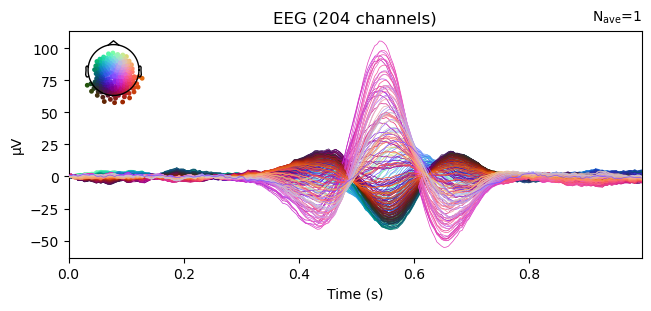

In [6]:
_ = data["eeg_inv"].plot()

#### 🌟 Visualize EEG topographic maps

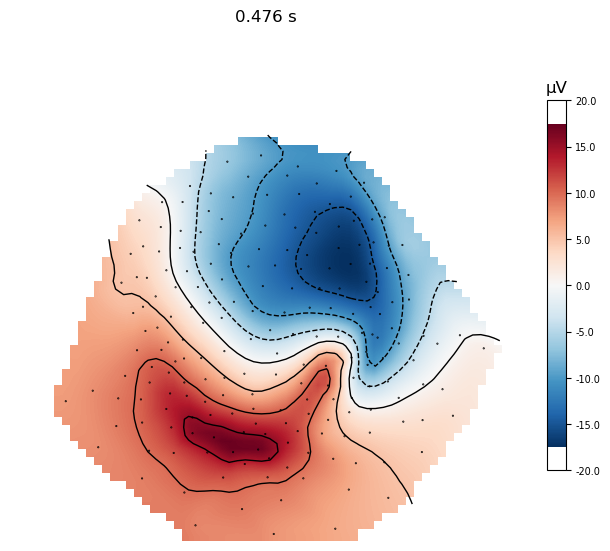

In [7]:
times = [0.476]
_ = data["eeg_inv"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

In [8]:
arr1 = np.abs(data["lam"] - np.roll(data["lam"], 1))
arr2 = np.abs(data["lam"] - np.roll(data["lam"], -1))
D    = np.minimum(arr1, arr2)**0.125

mm.viz.plot_spectrum(D).show()

## Select a Time point

🛠️ <font color=violet>**Select a time window to reconstruct**</font>: One time sample takes around 1 second to reconstruct.
- Window size (`win_size`): time window around EEG peak in [s]

Number of samples: 24


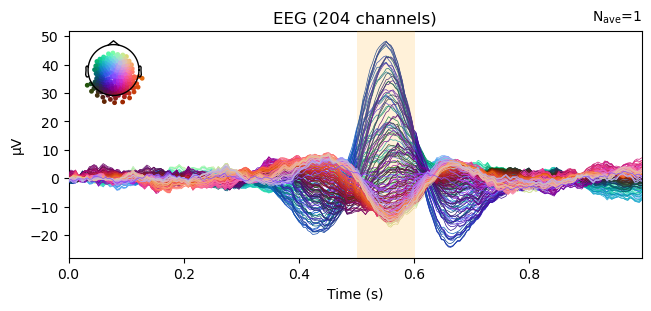

In [9]:
win_size = 0.1      # window size in [s], if None take the 50% rising phase and peak phase only

if win_size is not None:
    dt = int(win_size * sfreq /2)
    Y  = data["eeg_inv"].data[:, pt-dt:pt+dt]

    t_start  = t_peak-(win_size/2)
    t_end    = t_peak+(win_size/2)
    idx_half = int((t_half-t_start)*sfreq)
    idx_peak = int((t_peak-t_start)*sfreq)

    highlight = [t_start, t_end]

else:
    Y = data["eeg_inv"].data[:, [ht,pt]]

    idx_half = 0
    idx_peak = 1

    highlight = [t_half-1e-3, t_half+1e-3], [t_peak-1e-3, t_peak+1e-3]

print(f"Number of samples: {Y.shape[1]}")
_ = data["eeg_inv"].plot(highlight=highlight)

## Solve The Inverse Problem with CSET

🛠️ <font color=violet>**Select CSET parameters**</font> 
- $\lambda$ (`lam`): regularizer parameter (influences the connectome spectrum sparsity)

In [32]:
lam = 1             # cst smoothness regularizer
dw  = 0             # depth weighting regularizer
hw  = 0.5             # harmonic regularizer

cut_freq = None     # cst cut off frequency

scale = 1e0         # pyxu does not optimize for small scale so this scales data to big numbers (for optimization) and then descales (for values)

⚙️ <font color=green>**Solve inverse problem**</font>: Using the `pyxu` package we can write down any optimization problem and then solve them.

In [33]:
# ----- Optimization problem -----

# frequency cutoff
if cut_freq is not None:
    cst = data["cst"][:cut_freq,:]
else:
    cst = data["cst"]

# Harmonic covariance matrix
arr1 = np.abs(data["lam"] - np.roll(data["lam"], 1))
arr2 = np.abs(data["lam"] - np.roll(data["lam"], -1))
D    = np.minimum(arr1, arr2)**hw
D    = D/np.linalg.norm(D)
D    = np.diag(D)

# standardize
Ynorms = np.linalg.norm(Y, axis=0)
Y      = Y/Ynorms[None,:]

L      = fwd - np.mean(fwd, axis=0)
Lnorms = np.linalg.norm(L, axis=0)**dw
L      = L/Lnorms[None,:]

# weighted component-wise transformation
L = L @ cst.T @ D


# pyxu components
L     = pxa.LinOp.from_array(L)
prior = lam * pxo.SquaredL2Norm(dim_shape=cst.shape[0])
recon = np.zeros((cst.shape[1], Y.shape[1]))
sc    = pxst.MaxIter(1000)


# ----- Optimization solving -----

for t in range(Y.shape[1]):
    y     = Y[:,t]                                      # data time point
    s_hat = np.random.random(L.dim_shape)*10**(-9)      # initial guess

    likelihood = pxo.SquaredL2Norm(dim_shape=L.codim_shape).argshift(-y)*L + prior
    likelihood.diff_lipschitz = likelihood.estimate_diff_lipschitz()

    solver = PGD(f=likelihood, g=None, show_progress=False)

    solver.fit(x0=s_hat, stop_crit=sc)

    s_hat      = solver.solution().squeeze()
    recon[:,t] = (cst.T @ s_hat) * Ynorms[t] / scale

#### <font color=yellow>🌟</font> Visualize reconstruction

In [44]:
viz = np.abs(recon)/(np.max(np.abs(recon), axis=0)+1e-15)
std = np.std(viz)
viz = viz>6*std

mm.viz.plot_brain_time_series(data["fwd"]["src"], viz, t_start=t_start, sfreq=sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:43877/index.html?ui=P_0x73041086fb00_39&reconnect=auto" class="pyv…

In [76]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(recon[:,idx_half]), cmap="reds").show()

Widget(value='<iframe src="http://localhost:33367/index.html?ui=P_0x7562ecdca600_50&reconnect=auto" class="pyv…

In [31]:
mm.viz.plot_spectrum(data["cst"]@recon[:,idx_half])

#### 💾 Save result

In [ ]:
fname  = f"{sub}_cset-{lam}"
folder = Path(config["MM_DIR"])/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving source time course of {sub}, {sample}")
vertices = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]
stc = mne.SourceEstimate(recon, vertices, tmin=t_start, tstep=1/sfreq, subject=sub)
stc.save(folder/fname, overwrite=True, verbose="warning")

Saving source time course of sub-pat18, 


# Applying CSET on dataset

## 📦 Imports

In [17]:
import mindmap as mm 
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- Configuration file (`config`)
- `subjects`: list of subjects to process
- `samples`: list of samples to process


🎚️ **<font color=pink>Parameters</font>**
- Regularizer parameter (`lam`)
- Time window size (`win_size`)
- Depth Weighting scale (`dw`)
- Scale (`scale`)

In [18]:
# config
config   = mm.io.read_config("../configurations/simf.yml")
subjects = config["SUBS"]
samples  = config["SAMP"]
mm_dir   = Path(config["MM_DIR"])
fname    = lambda sub, samp, lam: mm_dir/sub/"inv"/f"{sub}_{samp}_wcset-{lam}"

# parameters
win_size = 0.1 
lam      = 0.1 
dw       = 1/2
hw       = 1/3
scale    = 1

In [20]:
for sub in config["SUBS"]:
    for samp in config["SAMP"]:
        try: 
            data = mm.io.read_dataset(sub, "eeg_inv", "fwd", "cst", "lam", sample=samp)
            stc  = mm.wcset(data["eeg_inv"], data["fwd"], data["cst"], data["lam"], lam, dw, hw, win_size, scale, sub)
        except Exception as e:
            print(f"\033[91mSkipped {sub}, {samp} due to {e}\033[0m")
            continue

        file = fname(sub, samp, lam)
        if not file.parent.exists():
            file.parent.mkdir()

        stc.save(fname(sub, samp, lam), overwrite=True, verbose="warning")
        print(f"\033[92m{sub}, {samp} successfully reconstructed\033[0m")

vepcon_sub-10, sample1 successfully reconstructed
vepcon_sub-10, sample2 successfully reconstructed
vepcon_sub-10, sample3 successfully reconstructed
vepcon_sub-10, sample4 successfully reconstructed
vepcon_sub-10, sample5 successfully reconstructed
vepcon_sub-10, sample6 successfully reconstructed
vepcon_sub-10, sample7 successfully reconstructed
vepcon_sub-10, sample8 successfully reconstructed
vepcon_sub-10, sample9 successfully reconstructed
vepcon_sub-10, sample10 successfully reconstructed
vepcon_sub-10, sample11 successfully reconstructed
vepcon_sub-10, sample12 successfully reconstructed
vepcon_sub-10, sample13 successfully reconstructed
vepcon_sub-10, sample14 successfully reconstructed
vepcon_sub-10, sample15 successfully reconstructed
vepcon_sub-10, sample16 successfully reconstructed
vepcon_sub-10, sample17 successfully reconstructed
vepcon_sub-10, sample18 successfully reconstructed
vepcon_sub-10, sample19 successfully reconstructed
vepcon_sub-10, sample20 successfully rec